# Phase 2: resource limits and shrimp mortality

This phase extends the base shrimp/algae/bird model with logistic algae growth and natural shrimp mortality.

Can adding a algae carrying capacity and natural shrimp death rate sustain stable coexistence across a range of bird mortality rates?



## Units and parameter guesses

Time is in days; algae `A` is water chlorophyll-a in µg Chl-a/L; shrimp `S` is individuals/L; birds `B` is individuals. Chlorophyll represents the algae community, with *Dunaliella viridis* as the focal food species. Almost all values below are guesses to allow analysis of behavior of the model, calibration would be needed to make this better align with reality..

| Parameter | Meaning | Value | Units | Brief justification |
|---|---|---|---|---|
| `beta_A` | Algae growth rate | 0.3 | day⁻¹ | Full-blown guess |
| `K` | Algae carrying capacity | 50 | µg Chl-a/L | Full-blown guess |
| `C_A` | Shrimp clearance coefficient | 0.02 | L/(shrimp day) | Guess informed by Makridis & Vadstein, 1999 |
| `C_S` | Effective bird feeding coefficient | 0.4 | 1/(bird day) | Full-blown guess |
| `gamma_S` | Shrimp gain per chlorophyll loss | 0.2 | shrimp/(µg Chl-a) | Full-blown guess |
| `gamma_B` | Bird gain per shrimp density loss | 0.3 | bird L/shrimp | Full-blown guess |
| `delta_S` | Shrimp natural mortality | 0.03 | day⁻¹ | Full-blown guess |
| `delta_B` | Bird natural mortality | 0.12 | day⁻¹ | Full-blown guess |

Initial conditions: `S0 = 1` shrimp/L, `A0 = 10` µg Chl-a/L, `B0 = 1` bird. I used AI to format this table.

## Equations

$$
\frac{dS}{dt} = \gamma_S C_A S A - C_S S B - \delta_S S
$$

$$
\frac{dA}{dt} = \beta_A A(1-A/K) - C_A S A
$$

$$
\frac{dB}{dt} = -\delta_B B + \gamma_B C_S S B
$$

$K>0$ is the algae carrying capacity in the absence of grazing. $\delta_S>0$ is the shrimp natural mortality rate. All other terms retain the same meanings as in phase 1. 

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

beta_A = 0.3  # Guessed daily algae growth
C_A = 0.02  # More educated guess of how much algae the shrimp eat L/(shrimp day)
C_S = 0.4 # Guess of how much shrimp the birds eat
gamma_S = 0.2  # algae-to-shrimp conversion
gamma_B = 0.3 # shrimp-to-bird conversion
delta_B = 0.12 # bird death rate
K = 50.0       # algae carrying capacity
delta_S = 0.03  # shrimp mortality


y0 = np.array([1.0, 10.0, 1.0])  # Initial conditions: shrimp, algae, birds
T = 400.0


In [9]:
def rhs(t, state, bird_mortality):
    S, A, B = state
    return np.array([
        gamma_S*C_A*S*A - C_S*S*B - delta_S*S,
        beta_A*A*(1 - A/K) - C_A*S*A,
        -bird_mortality*B + gamma_B*C_S*S*B,
    ])

def simulate(initial, duration, bird_mortality):
    initial = np.asarray(initial, dtype=float)
    if initial.shape != (3,) or np.any(initial < 0):
        raise ValueError('Initial state must contain three nonnegative populations.')
    sol = solve_ivp(lambda t, y: rhs(t, y, bird_mortality), (0, duration), initial,
                    t_eval=np.linspace(0, duration, 2401), rtol=1e-8, atol=1e-10)
    if not sol.success:
        raise RuntimeError(sol.message)
    if np.min(sol.y) < -1e-7:
        raise RuntimeError('Negative numerical populations: inspect solver settings.')
    return sol

sol = simulate(y0, T, delta_B)

## equilibrium

We want to find equilibrium, but we only care about where we have positive populations, so we will need to be careful with our guesses for the parameters. The values we have picked ensure that the equilibrium point has positive populations. Doing some algebra, this is what we get for equilibrium points.

$$
S^* = \frac{\delta_B}{\gamma_B C_S}
$$

$$
A^* = K\left(1-\frac{C_A S^*}{\beta_A}\right)
$$

$$
B^* = \frac{\gamma_S C_A A^* - \delta_S}{C_S}
$$



In [14]:
def equilibrium():
    S = delta_B/(gamma_B*C_S)
    A = K*(1 - C_A*S/beta_A)
    B = (gamma_S*C_A*A - delta_S)/C_S
    return np.array([S, A, B])

def jacobian(state):
    S, A, B = state
    return np.array([
        [gamma_S*C_A*A-C_S*B-delta_S, gamma_S*C_A*S, -C_S*S],
        [-C_A*A, beta_A*(1-2*A/K)-C_A*S, 0],
        [gamma_B*C_S*B, 0, -delta_B+gamma_B*C_S*S],
    ])

eq = equilibrium()
threshold = gamma_B*C_S*beta_A/C_A*(1-delta_S/(gamma_S*C_A*K))
print('Equilibrium point [S, A, B]:', eq)
if np.all(eq > 0):
    assert np.allclose(rhs(0, eq, delta_B), 0, atol=1e-10)
    eigenvalues = np.linalg.eigvals(jacobian(eq))
    print('Jacobian eigenvalues:', eigenvalues)
    print('Locally stable:', np.all(eigenvalues.real < 0))
else:
    print('The equilibrium point is not strictly positive for these parameters.')

Equilibrium point [S, A, B]: [ 1.         46.66666667  0.39166667]
Jacobian eigenvalues: [-0.26898319+0.j         -0.00550841+0.13978431j -0.00550841-0.13978431j]
Locally stable: True


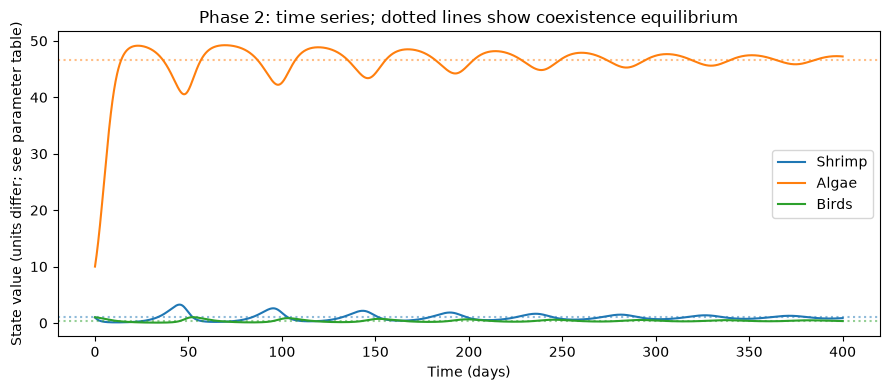

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
for i, label in enumerate(['Shrimp', 'Algae', 'Birds']):
    line, = ax.plot(sol.t, sol.y[i], label=label)
    if np.all(eq > 0):
        ax.axhline(eq[i], color=line.get_color(), linestyle=':', alpha=0.5)
ax.set(xlabel='Time (days)', ylabel='State value (units differ; see parameter table)',
       title='Phase 2: time series; dotted lines show coexistence equilibrium')
ax.legend()
fig.tight_layout()
plt.show()

## Shrimp/algae phase portrait without birds

Setting $B=0$ gives a two-dimensional subsystem. Its nonzero nullclines are $A=\delta_S/(\gamma_S C_A)$ and $S=(\beta_A/C_A)(1-A/K)$. 

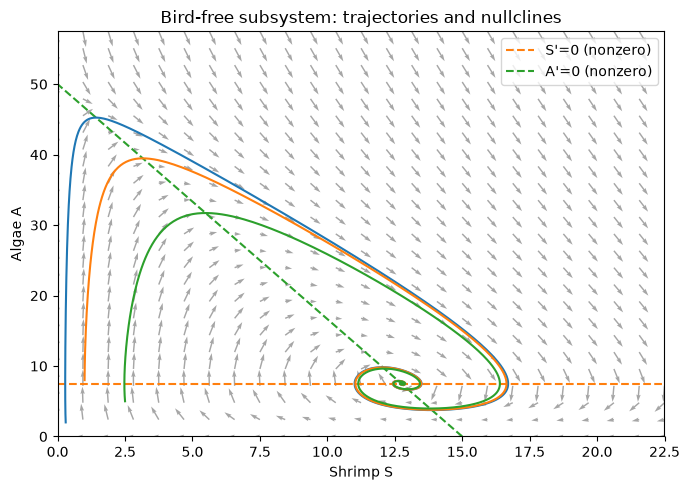

In [ ]:
# I used AI to make these plots pretty, but I solved for the nullclines myself.

Smax = 1.5*beta_A/C_A
Amax = 1.15*K
sg = np.linspace(0, Smax, 25)
ag = np.linspace(0, Amax, 25)
SS, AA = np.meshgrid(sg, ag)
dS = SS*(gamma_S*C_A*AA-delta_S)
dA = AA*(beta_A*(1-AA/K)-C_A*SS)
# Normalize by each axis range to keep direction arrows readable.
speed = np.hypot(dS/Smax, dA/Amax)
scale = np.maximum(speed, 1e-12)
fig, ax = plt.subplots(figsize=(7, 5))
ax.quiver(SS, AA, dS/scale, dA/scale, alpha=0.35, angles='xy')
ax.axhline(delta_S/(gamma_S*C_A), color='tab:orange', linestyle='--', label="S'=0 (nonzero)")
a_line = np.linspace(0, K, 200)
ax.plot(beta_A/C_A*(1-a_line/K), a_line, '--', color='tab:green', label="A'=0 (nonzero)")
for initial in ([0.3, 2, 0], [1.0, 8, 0], [2.5, 5, 0]):
    trajectory = simulate(initial, T, delta_B)
    ax.plot(trajectory.y[0], trajectory.y[1], linewidth=1.5)
ax.set(xlim=(0, Smax), ylim=(0, Amax), xlabel='Shrimp S', ylabel='Algae A',
       title='Bird-free subsystem: trajectories and nullclines')
ax.legend()
fig.tight_layout()
plt.show()

## Change bird mortality

Compare mortality rates below and above the positive coexistence threshold. The simulations use the same initial populations. 

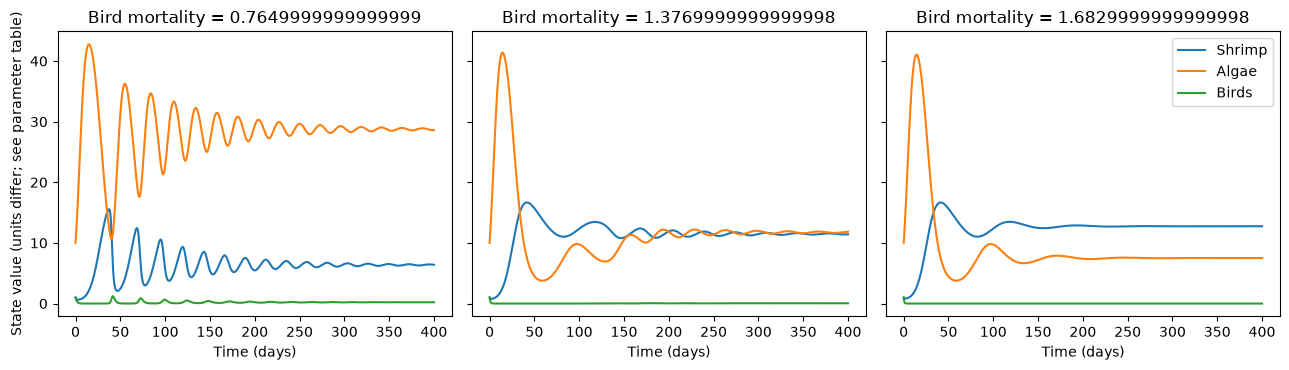

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharex=True, sharey=True)
for ax, mortality in zip(axes, [0.5*threshold, 0.9*threshold, 1.1*threshold]):
    result = simulate(y0, T, mortality)
    for i, label in enumerate(['Shrimp', 'Algae', 'Birds']):
        ax.plot(result.t, result.y[i], label=label)
    ax.set(title=f'Bird mortality = {mortality}', xlabel='Time (days)')
axes[0].set_ylabel('State value (units differ; see parameter table)')
axes[-1].legend()
fig.tight_layout()
plt.show()

1. [Makridis and Vadstein (1999), Food size selectivity of Artemia franciscana at three developmental stages](https://academic.oup.com/plankt/article-abstract/21/11/2191/1499662). The abstract reports maximum clearance rates of 50-63 microliters/individual/hour at 2 days old, 254 at 4 days, and 1.48-2.10 milliliters/individual/hour at 7 days. Converted by multiplying by 24 and converting to liters, these are 0.0012-0.001512, 0.006096, and 0.03552-0.0504 L/(individual day). These are laboratory maximum rates across tested particles, not a *D. viridis*-specific field estimate. They support exploring a broad feeding scale; `C_A=0.02` is our intermediate guess, not a reported experimental result.

-- AI helped me find this source.